# Credit Card Fraud Detection

## Objective
The objective of this project is to build a machine learning model that can detect fraudulent credit card transactions. The model learns patterns from transaction data and predicts whether a transaction is genuine or fraudulent.

---

## Dataset
The dataset contains credit card transactions made by European cardholders.

- Features: Time, Amount, V1 to V28
- Target:
  - 0 = Genuine Transaction
  - 1 = Fraudulent Transaction

---

## Technologies Used
- Python
- Pandas
- NumPy
- Matplotlib
- Scikit-learn

---

## Machine Learning Algorithm
- Logistic Regression

In [19]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

## Step 1: Load the Dataset

In [3]:
# Load the dataset

df = pd.read_csv("creditcard.csv")

# Display first five rows
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## Step 2: Explore the Dataset

In [4]:
# Dataset information

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [5]:
# Statistical summary

df.describe()
# Check missing values

df.isnull().sum()

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

## Step 3: Analyze the Target Variable

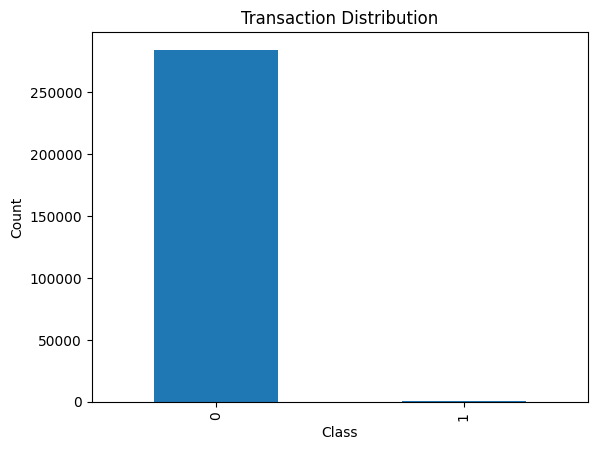

In [6]:
# Count genuine and fraud transactions

df['Class'].value_counts()
# Plot transaction distribution

df['Class'].value_counts().plot(kind='bar')

plt.title("Transaction Distribution")
plt.xlabel("Class")
plt.ylabel("Count")
plt.show()

## Step 4: Split Features and Target

In [7]:
# Separate input and output

X = df.drop('Class', axis=1)
y = df['Class']

## Step 5: Split Training and Testing Data

In [8]:
# Split dataset

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

## Step 6: Train the Model

In [20]:
# Create Logistic Regression model

model = RandomForestClassifier(n_estimators=50,class_weight='balanced',n_jobs=-1,random_state=42)

# Train model

model.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', n_estimators=50, n_jobs=-1,
                       random_state=42)

## Step 7: Make Predictions

In [21]:
# Predict test data

y_pred = model.predict(X_test)

## Step 8: Evaluate the Model

In [22]:
# Calculate accuracy

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.9995786664794073


## Step 9: Detailed Evaluation

[[56863     1]
 [   23    75]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.99      0.77      0.86        98

    accuracy                           1.00     56962
   macro avg       0.99      0.88      0.93     56962
weighted avg       1.00      1.00      1.00     56962



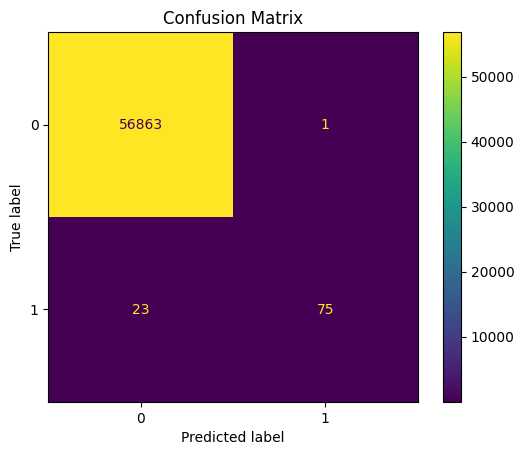

In [23]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Confusion matrix values
print(confusion_matrix(y_test, y_pred))

# Precision, recall, F1-score
print(classification_report(y_test, y_pred))

# Confusion matrix plot
ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.title("Confusion Matrix")
plt.show()

## Step 10: Save the Model

In [24]:
import joblib
joblib.dump(model, "model.pkl")

['model.pkl']

In [25]:
genuine = X_train[y_train == 0]
ref = {"mean": genuine.mean(), "std": genuine.std()}
joblib.dump(ref, "reference.pkl")

['reference.pkl']

In [26]:
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix

genuine = X_train[y_train == 0]
joblib.dump({"mean": genuine.mean(), "std": genuine.std()}, "reference.pkl")

metrics = {
    "accuracy": accuracy_score(y_test, y_pred),
    "precision": precision_score(y_test, y_pred),
    "recall": recall_score(y_test, y_pred),
    "f1": f1_score(y_test, y_pred),
    "cm": confusion_matrix(y_test, y_pred).tolist(),
}
joblib.dump(metrics, "metrics.pkl")

['metrics.pkl']

# Conclusion

The Logistic Regression model was successfully trained to detect fraudulent credit card transactions. The dataset was explored, split into training and testing sets, and used to build a predictive model. Finally, the model's performance was evaluated using accuracy.

This project demonstrates how machine learning can help identify fraudulent financial transactions efficiently.